In [2]:
import os
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch

# Core crack_seg imports
from crack_seg import config
from crack_seg.data_handlers.dataset_loaders import get_train_val_test_datasets
from crack_seg.data_handlers.transforms import val_transform, pred_transform
from crack_seg.utils.helpers import load_model, predict_yolo_mask


Loading UNet model...
Loading SegFormer model...
Loading YOLO model...

Visualizing 20 test samples across 3 models...



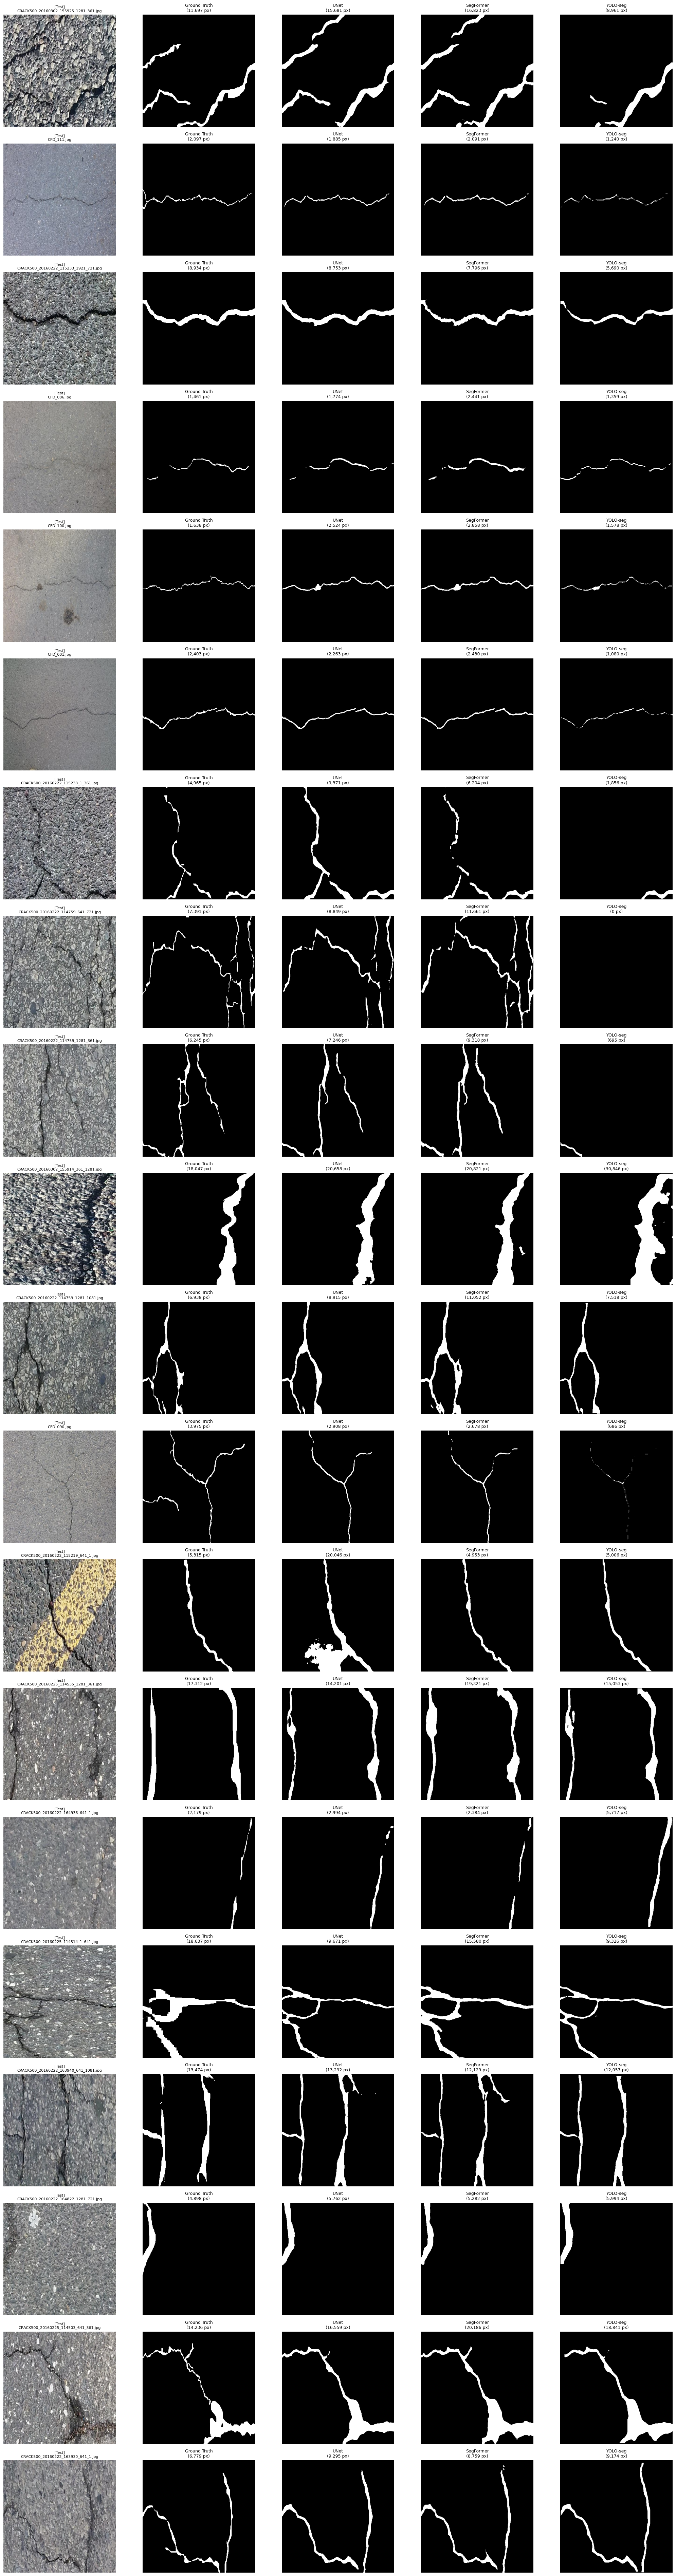

In [4]:
# ==============================================================================
# Compare Trained UNet, SegFormer, and YOLO Models on Random Test Samples
# ==============================================================================

# ------------------------------------------------------------------------------
# 1. Model Checkpoint Paths & Loading
# ------------------------------------------------------------------------------
unet_checkpoint = config.CHECKPOINT_DIR / "unet_CConCrack_NCCD-PF_Dataset_DeepCrack_CRACK500.pth"
segformer_checkpoint = config.CHECKPOINT_DIR / "segformer_CConCrack_NCCD-PF_Dataset_DeepCrack_CRACK500.pth"
yolo_checkpoint = config.CHECKPOINT_DIR / "yolo_runs" / "yolo_seg_CConCrack_NCCD-PF_Dataset_DeepCrack_CRACK500.pt"

# Load UNet, SegFormer, and YOLO models
print("Loading UNet model...")
unet_model = load_model("unet", unet_checkpoint, device=config.DEVICE)

print("Loading SegFormer model...")
segformer_model = load_model("segformer", segformer_checkpoint, device=config.DEVICE)

print("Loading YOLO model...")
yolo_model = load_model("yolo", yolo_checkpoint, device=config.DEVICE)

# Define models with their types for inference
models_to_plot = {
    "UNet": ("unet", unet_model),
    "SegFormer": ("segformer", segformer_model),
    "YOLO-seg": ("yolo", yolo_model),
}

# ------------------------------------------------------------------------------
# 2. Load Held-Out Test Split
# ------------------------------------------------------------------------------
if "test_ds" not in globals():
    _, _, test_ds = get_train_val_test_datasets(
        train_transform=val_transform,
        val_transform=val_transform,
        dataset_names=config.DATASETS,
        data_root=config.DATA_ROOT,
        train_ratio=config.TRAIN_RATIO,
        val_ratio=config.VAL_RATIO,
        test_ratio=config.TEST_RATIO,
        seed=config.SPLIT_SEED,
        stratified=config.STRATIFIED_SPLIT,
    )

# ------------------------------------------------------------------------------
# 3. Select 10 Samples Containing Noticeable Cracks
# ------------------------------------------------------------------------------
rng = np.random.default_rng(10)
candidate_pool = min(600, len(test_ds.samples))
cracked_indices = []

for idx in range(candidate_pool):
    mask_p = test_ds.samples[idx][1]
    m_arr = np.array(Image.open(mask_p).convert("L"))
    if (m_arr >= config.MASK_THRESHOLD).sum() > 300:
        cracked_indices.append(idx)
    if len(cracked_indices) >= 50:
        break

if len(cracked_indices) >= 10:
    sample_indices = rng.choice(cracked_indices, size=20, replace=False)
else:
    sample_indices = rng.choice(len(test_ds.samples), size=min(10, len(test_ds.samples)), replace=False)

print(f"\nVisualizing {len(sample_indices)} test samples across {len(models_to_plot)} models...\n")

# ------------------------------------------------------------------------------
# 4. Generate Multi-Model Comparison Figure
# ------------------------------------------------------------------------------
num_cols = 2 + len(models_to_plot)  # Image + Ground Truth + Models
fig, axes = plt.subplots(
    len(sample_indices),
    num_cols,
    figsize=(4.2 * num_cols, 3.8 * len(sample_indices)),
)
if len(sample_indices) == 1:
    axes = np.expand_dims(axes, axis=0)

for row_idx, sample_idx in enumerate(sample_indices):
    image_path, mask_path = test_ds.samples[int(sample_idx)]
    img_p = Path(image_path)

    # Dataset name detection from directory hierarchy
    ds_origin = (
        img_p.parent.parent.name
        if "images" in img_p.parent.name.lower() or "masks" in img_p.parent.name.lower()
        else img_p.parent.name
    )

    image = Image.open(image_path).convert("RGB")
    ground_truth = Image.open(mask_path).convert("L")
    orig_w, orig_h = image.size

    # Standardize views to model resolution (448, 448)
    image_disp = image.resize(config.IMG_SIZE, Image.Resampling.BILINEAR)
    gt_disp = (
        np.array(ground_truth.resize(config.IMG_SIZE, Image.Resampling.NEAREST))
        >= config.MASK_THRESHOLD
    ).astype(np.uint8) * 255

    # Col 0: Original Image
    axes[row_idx, 0].imshow(image_disp)
    axes[row_idx, 0].set_title(f"[{ds_origin}]\n{img_p.name}", fontsize=8)
    axes[row_idx, 0].axis("off")

    # Col 1: Ground Truth Mask
    axes[row_idx, 1].imshow(gt_disp, cmap="gray", vmin=0, vmax=255)
    axes[row_idx, 1].set_title(f"Ground Truth\n({gt_disp.sum() // 255:,} px)", fontsize=9)
    axes[row_idx, 1].axis("off")

    # Pre-transform image once for all PyTorch models (UNet, SegFormer)
    model_input = pred_transform(image).unsqueeze(0).to(config.DEVICE)

    # Columns 2+: Active Model Predictions
    with torch.no_grad():
        for col_idx, (name, (m_type, m_obj)) in enumerate(models_to_plot.items(), start=2):
            if m_type == "yolo":
                # Fast in-memory YOLO inference
                yolo_res = m_obj.predict(source=image, conf=0.25, imgsz=config.IMG_SIZE[0], verbose=False)[0]
                yolo_mask = np.zeros((orig_h, orig_w), dtype=np.uint8)
                if yolo_res.masks is not None:
                    for inst in yolo_res.masks.data.cpu().numpy():
                        inst_m = cv2.resize(
                            (inst > 0.5).astype(np.uint8) * 255,
                            (orig_w, orig_h),
                            interpolation=cv2.INTER_NEAREST,
                        )
                        yolo_mask = np.maximum(yolo_mask, inst_m)
                pred_disp = cv2.resize(yolo_mask, config.IMG_SIZE, interpolation=cv2.INTER_NEAREST)
            else:
                # Fast in-memory PyTorch inference (UNet, SegFormer)
                prob = torch.sigmoid(m_obj(model_input)).squeeze().cpu().numpy()
                pred_disp = (prob >= 0.5).astype(np.uint8) * 255

            axes[row_idx, col_idx].imshow(pred_disp, cmap="gray", vmin=0, vmax=255)
            axes[row_idx, col_idx].set_title(f"{name}\n({pred_disp.sum() // 255:,} px)", fontsize=9)
            axes[row_idx, col_idx].axis("off")

plt.tight_layout()
plt.show()
